[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pachterlab/OP_2025_2/blob/main/analysis_scripts/IRISeq.ipynb)

# A second assay: IRISeq (Supplementary Note 3, Fig. S6)

IRISeq (Abdulraouf et al., *Nature Neuroscience* 29, 1762–1773, 2026) is an optics-free assay of the same design as Hu et al.'s: separate sender and receiver beads, here 50 µm hydrogel beads mixed 3:1 (receivers:senders) and spread as a monolayer in a 0.6 × 0.6 cm square (the paper's Supplementary Note 1). Its authors reconstruct bead positions with PCA followed by UMAP. There is no imaging of bead positions, so this notebook shows only that accumap runs unchanged on a second assay and compares it with UMAP by criteria that need no ground truth:
1. the maximized Poisson log-likelihood of each layout;
2. accumap's contact-isotropy diagnostic (anisotropy relative to the level expected from sampling alone);
3. agreement between runs from different UMAP starts (overlap of each bead's 10 nearest neighbors);
4. spatial smoothness of gene expression (Moran's I) on each layout, including the layout published by the IRISeq authors (results table only: the differences are small, and it is not in Fig. S6).

**Data.** GEO GSE270383, section `FY1_2` (GSM8341579, a frontal section of a young female mouse). The connection file lists one row per molecule (receiver barcode, UMI, sender barcode), already corrected against the barcode whitelist and deduplicated. Beads with at least 100 connection UMIs are kept (97 percent of molecules); the remaining barcodes carry only a few UMIs each.

**A note on the GEO metadata.** In `GSE270383_meta_data.csv.gz`, the data columns (sample, totals, annotation, published coordinates) are misaligned with the row index of bead IDs: `nCount_RNA` equals the count matrix's per-bead total in only 0.02 percent of rows. Each row is therefore re-paired with the bead of the count matrix that has the same total UMIs and number of genes detected, keeping matches unique on both sides; after re-pairing, every row's sample label agrees with its bead ID.

In [ ]:
# Colab only: clone the repository (main branch) and install accumap; skipped when run locally
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("/content/OP_2025_2"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", "main", "https://github.com/pachterlab/OP_2025_2.git", "/content/OP_2025_2"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "/content/OP_2025_2"], check=True)
if "google.colab" in sys.modules:
    os.chdir("/content/OP_2025_2/analysis_scripts")

In [1]:
import os, json, gzip, urllib.request
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

RECOMPUTE = False                      # True: download GEO files (~1.3 GB) and rerun UMAP + accumap from 4 starts (GPU, ~15 min)
RESULTS = "paper_results"
OUTDIR = os.path.join(RESULTS, "iriseq_recomputed") if RECOMPUTE else os.path.join(RESULTS, "iriseq")
FIGURES = "../final_figures"
os.makedirs(OUTDIR, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEEDS = range(4)
SIDE = 6000.0                          # array side, um
MIN_UMI = 100
GEO = "https://ftp.ncbi.nlm.nih.gov/geo"
FILES = {"FY1_2.csv.gz": f"{GEO}/samples/GSM8341nnn/GSM8341579/suppl/GSM8341579_20231221_FY1_2_connection.spatial.csv.gz",
         "meta_data.csv.gz": f"{GEO}/series/GSE270nnn/GSE270383/suppl/GSE270383_meta_data.csv.gz",
         "count.mtx.gz": f"{GEO}/series/GSE270nnn/GSE270383/suppl/GSE270383_count.mtx.gz",
         "barcodes.tsv.gz": f"{GEO}/series/GSE270nnn/GSE270383/suppl/GSE270383_barcodes.tsv.gz",
         "genes.tsv.gz": f"{GEO}/series/GSE270nnn/GSE270383/suppl/GSE270383_genes.tsv.gz"}

## 1. Count matrix (`RECOMPUTE = True` only)

In [2]:
if RECOMPUTE:
    for name, url in FILES.items():
        path = os.path.join(OUTDIR, name)
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)
    rec, snd, rs, ss = {}, {}, [], []
    for ch in pd.read_csv(os.path.join(OUTDIR, "FY1_2.csv.gz"), header=None, names=["r", "umi", "s"], dtype=str, chunksize=5_000_000):
        rs.append(ch["r"].map(lambda x: rec.setdefault(x, len(rec))).to_numpy(np.int32))
        ss.append(ch["s"].map(lambda x: snd.setdefault(x, len(snd))).to_numpy(np.int32))
    r, s = np.concatenate(rs), np.concatenate(ss)
    C = sp.coo_matrix((np.ones(len(r), np.float32), (r, s)), shape=(len(rec), len(snd))).tocsr(); C.sum_duplicates()
    keep_r = np.asarray(C.sum(1)).ravel() >= MIN_UMI; keep_s = np.asarray(C.sum(0)).ravel() >= MIN_UMI
    print(f"{C.shape[0]:,} receiver and {C.shape[1]:,} sender barcodes, {int(C.sum()):,} molecules; "
          f"kept {keep_r.sum():,} x {keep_s.sum():,} with >= {MIN_UMI} UMIs ({C[keep_r][:, keep_s].sum() / C.sum():.0%} of molecules)")
    C = C[keep_r][:, keep_s].tocsr()
    sp.save_npz(os.path.join(OUTDIR, "counts.npz"), C)
    pd.Series(np.array(list(rec))[keep_r]).to_csv(os.path.join(OUTDIR, "receiver_barcodes.csv.gz"), index=False, header=False)

## 2. UMAP and accumap from 4 starts (`RECOMPUTE = True` only)

accumap runs with its defaults and the array's square outline as density footprint; `array_diameter` is the square's diagonal. For the log-likelihood comparison, the UMAP layout is scaled to the size of accumap's (and the best of five further scale factors is kept), with each sender at the count-weighted mean of its receivers, since UMAP places only receivers.

In [3]:
if RECOMPUTE:
    import accumap.count_model as cm
    C = sp.load_npz(os.path.join(OUTDIR, "counts.npz")).tocsr()
    square = np.array([[0, 0], [SIDE, 0], [SIDE, SIDE], [0, SIDE]], float) - SIDE / 2
    diam = SIDE * np.sqrt(2)
    W = sp.diags(1 / np.maximum(np.asarray(C.sum(0)).ravel(), 1)) @ C.T.tocsr()
    for seed in SEEDS:
        E = cm.umap_layout(C, seed=seed)
        R = cm.reconstruct(C, E, diam, device="cuda", verbose=False, footprint=square, log_passes=True)
        ll_acc = cm.log_likelihood(C, R["receivers"], diam, senders=R["senders"], device="cuda")
        X = R["receivers"]; Ec = E - E.mean(0); base = np.sqrt((X ** 2).sum(1).mean() / (Ec ** 2).sum(1).mean())
        ll_umap = max(cm.log_likelihood(C, Ec * base * f, diam, senders=np.asarray(W @ (Ec * base * f)), device="cuda")
                      for f in (0.6, 0.8, 1.0, 1.25, 1.5))
        ratio = [p["penalty"] / p["floor"] for p in R["pass_log"]]
        np.savez_compressed(os.path.join(OUTDIR, f"seed{seed}.npz"), umap=E, receivers=R["receivers"], senders=R["senders"])
        with open(os.path.join(OUTDIR, "runs.jsonl"), "a") as fh:
            fh.write(json.dumps({"seed": seed, "loglik_accumap": float(ll_acc), "loglik_umap": float(ll_umap), "anisotropy_ratio": ratio}) + "\n")
        print(seed, f"log-likelihood gain {ll_acc - ll_umap:.3g}", "anisotropy / sampling:", np.round(ratio, 2))

## 3. Re-paired metadata and gene expression (`RECOMPUTE = True` only)

Annotations and the published coordinates are attached to the receivers through the re-paired metadata; a bead ID in the metadata is the connection-file receiver barcode with dashes inserted. Gene expression of these receivers is normalized to 10,000 UMIs and log-transformed, and the 300 most variable genes detected in at least 5 percent of them are kept for Moran's I.

In [4]:
if RECOMPUTE:
    ncount = np.zeros(128405); nfeat = np.zeros(128405, int)
    for ch in pd.read_csv(os.path.join(OUTDIR, "count.mtx.gz"), sep=" ", skiprows=2, header=None, names=["g", "b", "v"], dtype=np.int64, chunksize=20_000_000):
        b = ch["b"].to_numpy() - 1; np.add.at(ncount, b, ch["v"].to_numpy()); np.add.at(nfeat, b, 1)
    bc = pd.read_csv(os.path.join(OUTDIR, "barcodes.tsv.gz"), header=None)[0].to_numpy()
    meta = pd.read_csv(os.path.join(OUTDIR, "meta_data.csv.gz"), index_col=0)
    print("rows whose nCount_RNA matches their own bead:", f"{np.mean(meta['nCount_RNA'].to_numpy() == ncount):.2%}")
    mat = pd.DataFrame({"bc": bc, "nc": ncount.astype(int), "nf": nfeat}).groupby(["nc", "nf"]).filter(lambda d: len(d) == 1)
    met = meta.reset_index(drop=True).rename(columns={"nCount_RNA": "nc", "nFeature_RNA": "nf"}).groupby(["nc", "nf"]).filter(lambda d: len(d) == 1)
    J = met.merge(mat, on=["nc", "nf"])
    agree = (J["bc"].str.split(".").str[0].str.replace("20231221_", "").str.replace("_cDNA", "") == J["orig.ident"]).mean()
    print(f"re-paired {len(J):,} of {len(meta):,} rows; sample label agrees with bead ID in {agree:.1%}")
    rec_bc = pd.read_csv(os.path.join(OUTDIR, "receiver_barcodes.csv.gz"), header=None)[0].to_numpy()
    pos = {b: i for i, b in enumerate(rec_bc)}
    J = J[J["bc"].str.startswith("20231221_FY1_2_cDNA.")].copy()
    J["conn"] = J["bc"].str.split(".").str[1].str.rsplit("-", n=1).str[0].str.replace("-", "")
    J = J[J["conn"].isin(pos) & J["UMAP1_spatial"].notna()]
    rows = J["conn"].map(pos).to_numpy()
    col = {b: i for i, b in enumerate(bc)}; cols = J["bc"].map(col).to_numpy()
    want = np.zeros(len(bc), bool); want[cols] = True; remap = -np.ones(len(bc), int); remap[cols] = np.arange(len(cols))
    parts = []
    for ch in pd.read_csv(os.path.join(OUTDIR, "count.mtx.gz"), sep=" ", skiprows=2, header=None, names=["g", "b", "v"], dtype=np.int64, chunksize=20_000_000):
        b = ch["b"].to_numpy() - 1; k = want[b]
        parts.append((remap[b[k]], ch["g"].to_numpy()[k] - 1, ch["v"].to_numpy()[k]))
    r, g, v = (np.concatenate(x) for x in zip(*parts))
    genes = pd.read_csv(os.path.join(OUTDIR, "genes.tsv.gz"), header=None, sep="\t").iloc[:, -1].to_numpy()
    X = sp.csr_matrix((v.astype(np.float32), (r, g)), shape=(len(cols), len(genes)))
    Xn = sp.diags(1e4 / np.asarray(X.sum(1)).ravel()) @ X; Xn.data = np.log1p(Xn.data); Xn = Xn.tocsc()
    cand = np.where(np.diff(Xn.indptr) / Xn.shape[0] >= 0.05)[0]
    sel = cand[np.argsort([Xn[:, j].toarray().var() for j in cand])[::-1][:300]]
    np.savez_compressed(os.path.join(OUTDIR, "expression.npz"), rows=rows, Y=Xn[:, sel].toarray().astype(np.float32), genes=genes[sel],
                        published=J[["UMAP1_spatial", "UMAP2_spatial"]].to_numpy(), annotation=J["Annotation"].to_numpy().astype(str))

## Results

In [5]:
runs = pd.read_json(os.path.join(OUTDIR, "runs.jsonl"), lines=True).set_index("seed")
Z = {s: np.load(os.path.join(OUTDIR, f"seed{s}.npz")) for s in SEEDS}
D = np.load(os.path.join(OUTDIR, "expression.npz"), allow_pickle=True)
rows, Y, published, lab = D["rows"], D["Y"] - D["Y"].mean(0), D["published"], D["annotation"]
n_rec = len(Z[0]["receivers"])

def knn(P, k=10):
    return NearestNeighbors(n_neighbors=k + 1).fit(P).kneighbors(P, return_distance=False)[:, 1:]

def overlap(P, Q):                      # mean Jaccard overlap of 10-NN sets
    return float(np.mean([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(knn(P), knn(Q))]))

def moran(P):                           # Moran's I of each gene over the 10-NN graph
    nb = knn(P)
    return (Y[:, None, :] * Y[nb]).mean(1).mean(0) / (Y ** 2).mean(0)

pairs = [(a, b) for i, a in enumerate(SEEDS) for b in SEEDS if b > a]
ov = {m: [overlap(Z[a][k], Z[b][k]) for a, b in pairs] for m, k in (("UMAP", "umap"), ("accumap", "receivers"))}
top50 = lambda I: float(np.sort(I)[::-1][:50].mean())
mi = {"IRISeq published": [top50(moran(published))],
      "UMAP": [top50(moran(Z[s]["umap"][rows])) for s in SEEDS],
      "accumap": [top50(moran(Z[s]["receivers"][rows])) for s in SEEDS]}
ratio = np.array(runs["anisotropy_ratio"].tolist())
summary = pd.DataFrame({
    "log-likelihood gain of accumap over UMAP": (runs["loglik_accumap"] - runs["loglik_umap"]).map(lambda x: f"{x:.3g}"),
    "anisotropy / sampling, stage 1": ratio[:, 0].round(2), "stage 2": ratio[:, 1].round(2),
    "Moran's I top 50, UMAP": np.round(mi["UMAP"], 3), "accumap": np.round(mi["accumap"], 3)})
print(f"{n_rec:,} receivers; {len(rows):,} with annotation and published coordinates")
print("10-NN overlap between starts: UMAP", round(np.mean(ov["UMAP"]), 2), " accumap", round(np.mean(ov["accumap"]), 2))
print("Moran's I top 50, IRISeq published layout:", round(mi["IRISeq published"][0], 3))
summary

7,289 receivers; 3,678 with annotation and published coordinates
10-NN overlap between starts: UMAP 0.63  accumap 0.81
Moran's I top 50, IRISeq published layout: 0.193


,log-likelihood gain of accumap over UMAP,"anisotropy / sampling, stage 1",stage 2,"Moran's I top 50, UMAP",accumap
seed,,,,,
0,2.04e+07,1.63,0.77,0.203,0.206
1,2.04e+07,1.42,0.84,0.202,0.206
2,2.04e+07,1.99,0.79,0.202,0.206
3,2.04e+07,1.79,0.96,0.202,0.206


## Fig. S6

Layouts are rotated and scaled (reflection allowed) to best match the published layout on the annotated receivers, for display only. Receivers without published coordinates are shown in light gray: mostly beads outside the tissue, which capture sender oligos but little mRNA and so were removed by the authors' gene-expression filter, plus a few hundred tissue beads whose metadata could not be re-paired uniquely. The published layout (A) contains only beads with published coordinates.

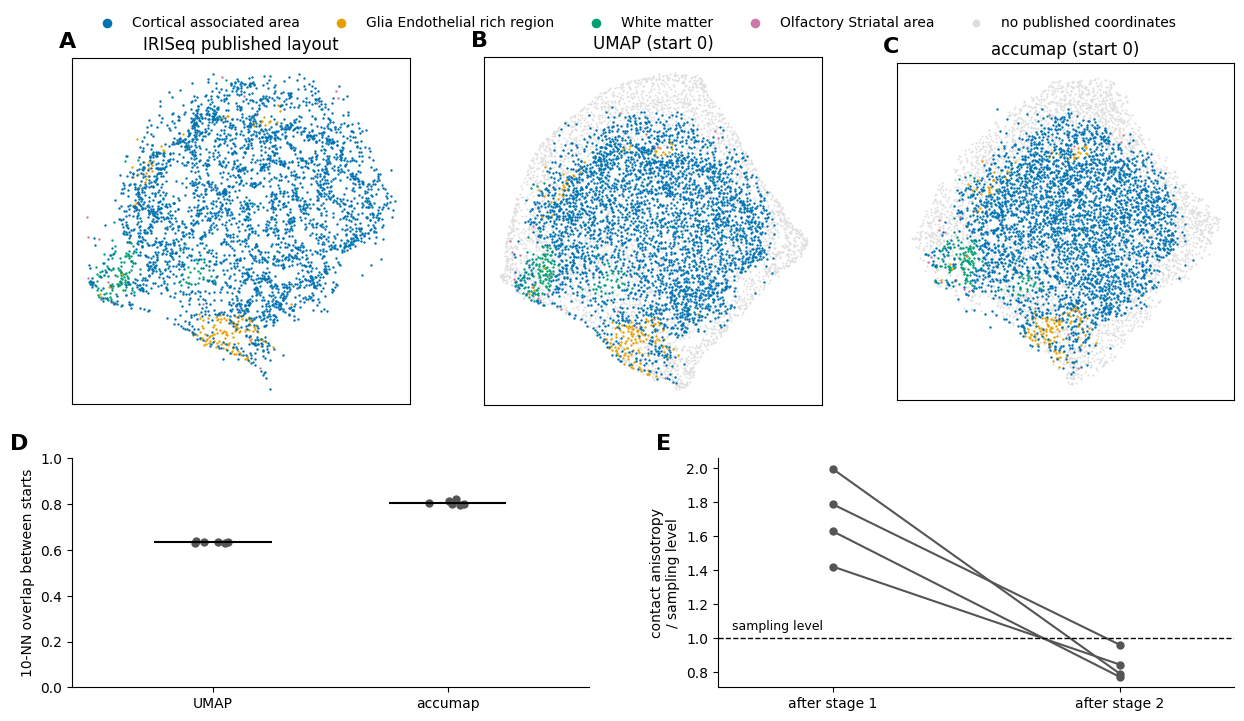

In [6]:
def align(P, ref, idx):                 # similarity transform (with reflection) of P fitted on P[idx] -> ref
    A, B = P[idx] - P[idx].mean(0), ref - ref.mean(0)
    U, S, Vt = np.linalg.svd(A.T @ B); Rm = U @ Vt; s = S.sum() / (A ** 2).sum()
    return (P - P[idx].mean(0)) @ Rm * s + ref.mean(0)

cats = pd.Series(lab).value_counts().index.tolist()
cols = dict(zip(cats, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]))
name = lambda c: c.replace("_section1", "").replace("_", " ")
fig = plt.figure(figsize=(15, 8.4))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 0.75], hspace=0.12, wspace=0.22)
gb = gs[1, :].subgridspec(1, 2, wspace=0.25)
panels = (("A", "IRISeq published layout", None), ("B", "UMAP (start 0)", Z[0]["umap"]), ("C", "accumap (start 0)", Z[0]["receivers"]))
for j, (letter, title, full) in enumerate(panels):
    ax = fig.add_subplot(gs[0, j])
    if full is None:
        P = published
    else:
        F = align(full, published, rows); P = F[rows]
        rest = np.setdiff1d(np.arange(len(F)), rows)
        ax.scatter(*F[rest].T, s=2, c="#DDDDDD", linewidths=0, rasterized=True, label="no published coordinates")
    for c in cats[::-1]:
        m = lab == c
        ax.scatter(*P[m].T, s=3, c=cols[c], linewidths=0, rasterized=True, label=name(c))
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    ax.text(-0.04, 1.03, letter, transform=ax.transAxes, fontsize=16, fontweight="bold")
h, l = ax.get_legend_handles_labels()
fig.legend(h[::-1], l[::-1], loc="upper center", ncol=5, markerscale=4, frameon=False, bbox_to_anchor=(0.5, 0.925))
axD, axF = fig.add_subplot(gb[0]), fig.add_subplot(gb[1])
rng = np.random.default_rng(0)
for i, m in enumerate(("UMAP", "accumap")):
    v = np.array(ov[m]); axD.scatter(i + rng.uniform(-0.08, 0.08, len(v)), v, s=25, c="#555555"); axD.hlines(v.mean(), i - 0.25, i + 0.25, color="k")
axD.set_xticks([0, 1], ["UMAP", "accumap"]); axD.set_xlim(-0.6, 1.6); axD.set_ylim(0, 1)
axD.set_ylabel("10-NN overlap between starts")
for r in ratio:
    axF.plot([0, 1], r, "-o", c="#555555", ms=5)
axF.axhline(1, ls="--", c="k", lw=1); axF.text(-0.35, 1.03, "sampling level", va="bottom", fontsize=9)
axF.set_xticks([0, 1], ["after stage 1", "after stage 2"]); axF.set_xlim(-0.4, 1.4)
axF.set_ylabel("contact anisotropy\n/ sampling level")
for ax, letter in zip((axD, axF), "DE"):
    ax.text(-0.12, 1.04, letter, transform=ax.transAxes, fontsize=16, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
plt.savefig(os.path.join(FIGURES, "FigS6_final.png"), dpi=300, bbox_inches="tight"); plt.show()